# Moirai 2.0 Zero-Shot Forecasting (1-Step Ahead Rolling)

Moirai 2.0 (thuộc thư viện `uni2ts` của Salesforce) là một mô hình Universal Time Series Transformer siêu mạnh mẽ. 
Notebook này sẽ hướng dẫn bạn dùng `Moirai-2.0-R-small` cho bài toán dự báo chứng khoán đa mã (Multivariate) bằng cách kết hợp với `gluonts`.

**Lưu ý quan trọng**: Bạn cần cài đặt thư viện `uni2ts` và `gluonts`. Hãy chạy ô bên dưới để cài.

In [3]:
# !git clone https://github.com/SalesforceAIResearch/uni2ts.git
# %cd uni2ts
# !pip install -e '.[notebook]'
# !pip install gluonts

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
ROOT_DIR   = Path.cwd().parent.parent
TRAIN_PATH = ROOT_DIR / "data" / "processed" / "v2" / "features_train.csv"
TEST_PATH  = ROOT_DIR / "data" / "processed" / "v2" / "features_test.csv"

In [2]:
# ========== 1. LOAD & CHUẨN BỊ DỮ LIỆU ĐA MÃ ==========
print("Đang load features_train và features_test...")
df_train = pd.read_csv(TRAIN_PATH, parse_dates=["Date"])
df_test  = pd.read_csv(TEST_PATH, parse_dates=["Date"])

df_all = pd.concat([df_train, df_test], ignore_index=True)

# Để dùng các mô hình Transformer như Moirai 2, ta cần chuỗi dữ liệu không bị đứt đoạn.
# Resample sang Business Days ('B') đối với mỗi ticker.
dfs = []
for ticker_id, group in df_all.groupby('ticker'):
    g_resampled = group.set_index('Date').resample('B').ffill()
    g_resampled['ticker'] = ticker_id
    dfs.append(g_resampled.reset_index())
    
df_ticker = pd.concat(dfs, ignore_index=True)
df_ticker = df_ticker[['ticker', 'Date', 'Close']]

print(f"Tổng số bản ghi sau resample: {len(df_ticker)} dòng trên {df_ticker['ticker'].nunique()} tickers.")

Đang load features_train và features_test...
Tổng số bản ghi sau resample: 50205 dòng trên 15 tickers.


In [3]:
# ========== 2. LOAD MÔ HÌNH MOIRAI 2.0 ==========
from uni2ts.model.moirai2 import Moirai2Forecast, Moirai2Module
from gluonts.dataset.pandas import PandasDataset
from gluonts.dataset.split import split

# Thiết lập Hyperparameters
MODEL_NAME = "Salesforce/moirai-2.0-R-small"
CONTEXT_LENGTH = 128     # Lịch sử 128 ngày
PREDICTION_LENGTH = 1    # Đoán đúng 1 ngày kế tiếp (mỗi lần trượt) 
TEST_WINDOWS = 30        # Trượt 30 lần (30 ngày cuối)

print(f"Đang tải {MODEL_NAME} từ HuggingFace...")
model = Moirai2Forecast(
    module=Moirai2Module.from_pretrained(MODEL_NAME),
    prediction_length=PREDICTION_LENGTH, # Moirai cần biết dự đoán bao xa mỗi nhịp
    context_length=CONTEXT_LENGTH,       # Moirai cần biết nhìn lại bao xa
    target_dim=1,
    feat_dynamic_real_dim=0,
    past_feat_dynamic_real_dim=0,
)

# Tạo predictor. Sử dụng batch_size để inference tốc độ cực cao
predictor = model.create_predictor(batch_size=64)
print("Load Moirai 2.0 hoàn tất!")

Đang tải Salesforce/moirai-2.0-R-small từ HuggingFace...


Load Moirai 2.0 hoàn tất!


In [4]:
# ========== 3. KHỞI TẠO TẬP DỮ LIỆU GLUONTS VÀ SLIDING WINDOW ==========
from gluonts.dataset.pandas import PandasDataset

# Sử dụng from_long_dataframe để hỗ trợ item_id và timestamp
ds = PandasDataset.from_long_dataframe(
    df_ticker,
    target="Close",
    item_id="ticker",
    timestamp="Date",
    freq="B"
)

print(f"Tạo tập Split: Bỏ đi {TEST_WINDOWS} ngày cuối để làm template Test...")
train_dataset, test_template = split(ds, offset=-TEST_WINDOWS)

print("Khởi tạo Rolling Windows...")
# Logic này của bạn rất chuẩn: tạo ra các cửa sổ trượt để test zero-shot
test_data = test_template.generate_instances(
    prediction_length=PREDICTION_LENGTH, 
    windows=TEST_WINDOWS,           
    distance=PREDICTION_LENGTH      
)

Tạo tập Split: Bỏ đi 30 ngày cuối để làm template Test...
Khởi tạo Rolling Windows...


In [5]:
# ========== 4. CHẠY INFERENCE ZERO-SHOT ==========
print("Bắt đầu chạy Dự báo hàng loạt (Predicting)...")
forecast_it = predictor.predict(test_data.input)
forecasts_list = list(forecast_it)
print(f"Tạo xong {len(forecasts_list)} dự báo cho {TEST_WINDOWS} cửa sổ trên toàn thị trường!")

Bắt đầu chạy Dự báo hàng loạt (Predicting)...
Tạo xong 450 dự báo cho 30 cửa sổ trên toàn thị trường!


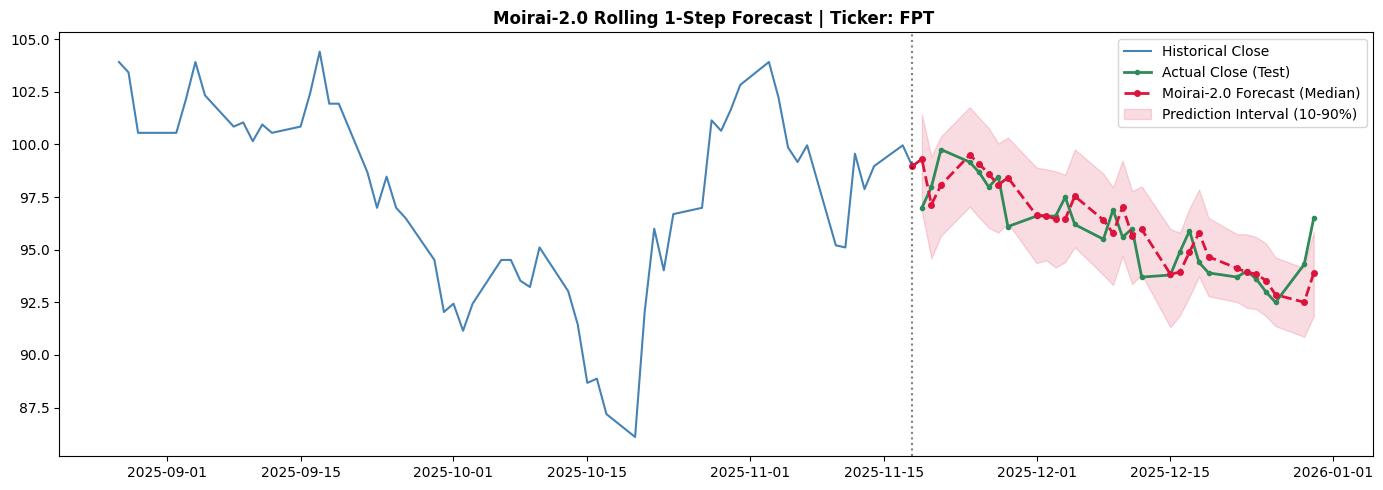

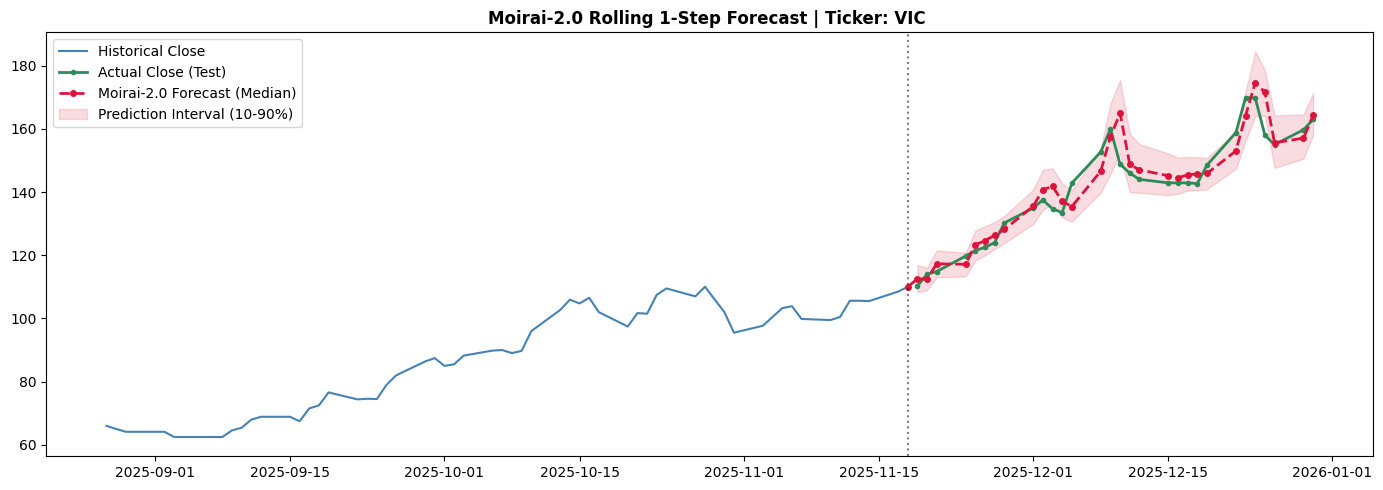

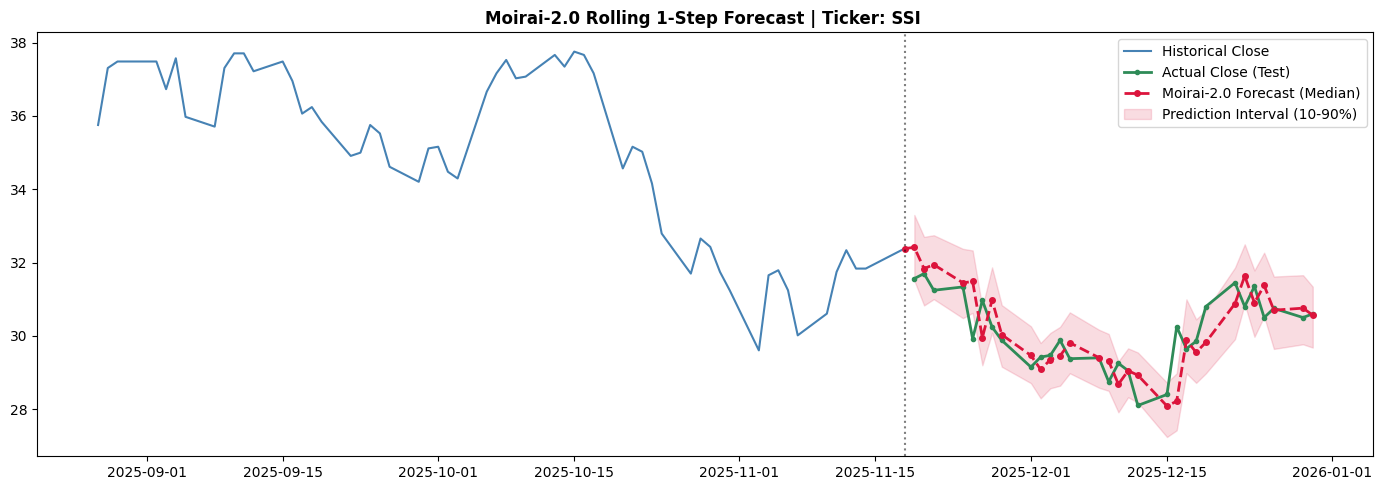

In [6]:
# ========== 5. RÁP KẾT QUẢ VÀ TRỰC QUAN HÓA ==========
# Trích xuất dữ liệu dự báo (P0.5 / Median) quay ngược lại Dataframe
# Chú ý: GluonTS giữ thứ tự tạo instances. Ta nhóm bằng item_id
results = []
for forecast in forecasts_list:
    ticker = forecast.item_id
    # start_date của forecast là một Period, chuyển sang Timestamp để vẽ biểu đồ
    pred_date = forecast.start_date.to_timestamp() 
    
    # Lấy giá trị tại bước dự báo đầu tiên [0] (vì PREDICTION_LENGTH = 1)
    # .quantile() nhận vào giá trị từ 0 đến 1 (0.5 tương đương Median)
    pred_close = forecast.quantile(0.5)[0] 
    q10 = forecast.quantile(0.1)[0]
    q90 = forecast.quantile(0.9)[0]
    
    results.append({
        "ticker": ticker,
        "Date": pred_date,
        "pred_close": pred_close,
        "pred_0.1": q10,
        "pred_0.9": q90
    })

df_preds = pd.DataFrame(results).sort_values(["ticker", "Date"]).reset_index(drop=True)

# Hàm vẽ biểu đồ minh họa
def plot_moirai_forecast(ticker_name, lookback_plot=60):
    # Dữ liệu dự đoán
    df_p = df_preds[df_preds['ticker'] == ticker_name].set_index("Date")
    
    if df_p.empty:
        print(f"Không có dữ liệu dự báo cho {ticker_name}")
        return
        
    start_test_date = df_p.index[0]
    
    # Lấy lịch sử 
    df_hist = df_ticker[(df_ticker['ticker'] == ticker_name) & (df_ticker['Date'] < start_test_date)].tail(lookback_plot).set_index("Date")
    df_actual = df_ticker[(df_ticker['ticker'] == ticker_name) & (df_ticker['Date'].isin(df_p.index))].set_index("Date")
    
    fig, ax = plt.subplots(figsize=(14, 5))
    
    # Vẽ giá quá khứ và thực tế
    ax.plot(df_hist.index, df_hist['Close'], label="Historical Close", color="steelblue", linewidth=1.5)
    ax.plot(df_actual.index, df_actual['Close'], label="Actual Close (Test)", color="seagreen", marker=".", linewidth=2)
    
    # Ghép gốc quá khứ vào dự đoán để nét vẽ liền mạch
    if not df_hist.empty:
        last_hist_val = df_hist['Close'].iloc[-1]
        last_hist_idx = df_hist.index[-1]
        padded_pred_idx = [last_hist_idx] + df_p.index.tolist()
        padded_pred_val = [last_hist_val] + df_p['pred_close'].tolist()
        
        ax.plot(padded_pred_idx, padded_pred_val, label="Moirai-2.0 Forecast (Median)", color="crimson", linewidth=2, linestyle="--", marker="o", markersize=4)
    else:
        ax.plot(df_p.index, df_p['pred_close'], label="Moirai-2.0 Forecast (Median)", color="crimson", linewidth=2, linestyle="--", marker="o", markersize=4)

    # Khoảng tin cậy
    ax.fill_between(
        df_p.index, df_p['pred_0.1'], df_p['pred_0.9'],
        color="crimson", alpha=0.15, label="Prediction Interval (10-90%)"
    )
    
    if not df_hist.empty:
        ax.axvline(x=df_hist.index[-1], color="black", linestyle=":", alpha=0.5)
        
    ax.set_title(f"Moirai-2.0 Rolling 1-Step Forecast | Ticker: {ticker_name} ", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.show()

# Trực quan thử
for tk in ["FPT", "VIC", "SSI"]:
    plot_moirai_forecast(tk)